# CompBench Mixed Prompt Agent Evaluation

Runs the MMEdit agent over the full CompBench annotation set using the mixed-modality instruction. The instruction preview names the exact selected visual prompt variable, for example `Remove <point_0>`, matching the object bound in the agent namespace. Set `RESUME_LAST_RUN = True` in the run cell to continue the latest run, skipping completed samples and retrying failed ones; otherwise each execution creates a fresh run. Shared JSONL/Hugging Face image loading, reference preparation, agent execution, and debug capture live in `evaluation/common.py`.

Install with `uv sync --extra models --extra benchmark`. This notebook loads `compbench_local_multiobject_mixed.jsonl` from the latest `.out/annotation/compbench/run_*/` by default. Set `MMEDIT_COMPBENCH_ANNOTATION_RUN=run_<timestamp>` to choose a run, or `MMEDIT_COMPBENCH_ANNOTATIONS` to provide an explicit JSONL path. Configure `MMEDIT_API_KEY` or `GOOGLE_API_KEY`. The run cell processes all annotations; use `compbench_debug.ipynb` for a representative sample from each task. HF image references use original split row indices.

Results are saved under `.out/evaluation/compbench/mixed/run_<timestamp>/`.

In [1]:
import matplotlib.pyplot as plt
from evaluation.notebook import create_run_directory, load_benchmark
from evaluation.common import annotate_sample, load_sample, run_benchmark, select_reference_prompts

BENCHMARK = "compbench"
PROMPT_MODE = "mixed"
context = load_benchmark(BENCHMARK, prompt_mode=PROMPT_MODE)
ANNOTATION_FILE = context.annotation_file
OUTPUT_ROOT = context.output_dir
records = context.records
image_loader = context.image_loader
print(f"{len(records)} CompBench annotations loaded from {ANNOTATION_FILE}")
print("Fields:", sorted(records[0]))

2609 CompBench annotations loaded from /Users/nghialt3670/Projects/MMEdit/mmedit-framework/.out/annotation/compbench/run_20261007_000000_000000/compbench_local_multiobject_mixed.jsonl
Fields: ['benchmark', 'linguistic_stats', 'metadata', 'mixed_instruction', 'original_instruction', 'parser_instruction', 'references', 'sample_id', 'source_ref', 'split', 'target_ref', 'validation']


remove:1dc12eca/0/00047.png remove <scribble_0>
Reference selectors: [{'token': '<scribble_0>', 'variable': 'scribble_0', 'refers_to': 'the second yellow bird on the left', 'box': [181, 298, 315, 375], 'point': [245.5, 340.5], 'scribble': True}]


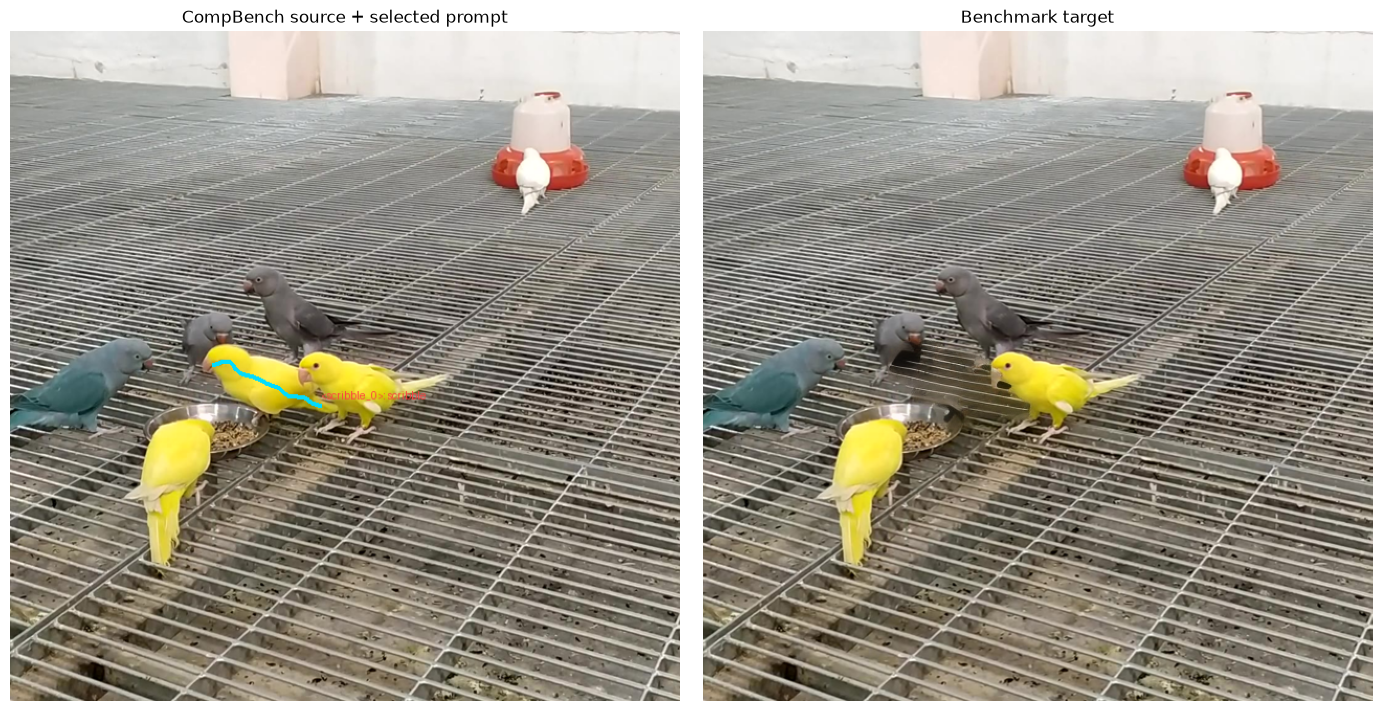

In [2]:
SAMPLE_INDEX = 962
record = records[SAMPLE_INDEX]
sample = load_sample(record, benchmark=BENCHMARK, image_loader=image_loader, prompt_mode=PROMPT_MODE)
if not sample["instruction"]:
    raise ValueError("CompBench record has no instruction.")
select_reference_prompts(sample)
print(sample["sample_id"], sample["instruction"])
print("Reference selectors:", [
    {
        "token": reference["display_token"],
        "variable": reference["selected_prompt"]["variable"] if reference["selected_prompt"] else None,
        "refers_to": reference["span"],
        "box": reference["bbox_xyxy"],
        "point": reference["point_xy"],
        "scribble": bool(reference["scribble_strokes"]),
    }
    for reference in sample["references"]
])
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(annotate_sample(sample))
axes[0].set_title("CompBench source + selected prompt")
axes[0].axis("off")
if sample["target_image"] is None:
    axes[1].text(0.5, 0.5, "No target image", ha="center", va="center")
else:
    axes[1].imshow(sample["target_image"])
axes[1].set_title("Benchmark target")
axes[1].axis("off")
plt.tight_layout()
plt.show()

In [3]:
from framework.tools import image_editing_tools
from evaluation.notebook import create_agent_model

llm = create_agent_model()
tools = image_editing_tools()
print("CompBench agent ready:", llm.model_id)

/Users/nghialt3670/Projects/MMEdit/mmedit-framework/.venv/lib/python3.13/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

The config attributes {'force_upcast': True} were passed to AutoencoderKLFlux2, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/1468 [00:00<?, ?it/s]

...

The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


CompBench agent ready: gemini-3.5-flash


In [6]:
# Annotation indices refer to the JSONL order; hf:// image refs retain original dataset row indices.
SAMPLE_INDICES = [821]
from evaluation.notebook import resolve_run_directory
RESUME_LAST_RUN = False  # True continues the latest run and skips completed samples.
RUN_DIR = resolve_run_directory(OUTPUT_ROOT) if RESUME_LAST_RUN else create_run_directory(OUTPUT_ROOT)
benchmark_results = run_benchmark(
    records,
    SAMPLE_INDICES,
    benchmark=BENCHMARK,
    prompt_mode=PROMPT_MODE,
    output_dir=RUN_DIR,
    image_loader=image_loader,
    model=llm,
    tools=tools,
    resume=RESUME_LAST_RUN,
    display_fn=None,
)
print("Run directory:", RUN_DIR)
print(f"Processed {len(benchmark_results)} CompBench samples.")

compbench inference:   0%|          | 0/1 [00:00<?, ?sample/s]

  0%|          | 0/8 [00:00<?, ?it/s]

Run directory: /Users/nghialt3670/Projects/MMEdit/mmedit-framework/.out/evaluation/compbench/mixed/run_20261012_093001_537770
Processed 1 CompBench samples.


In [5]:
completed = [result for result in benchmark_results if result["status"] == "completed"]
failed = [result for result in benchmark_results if result["status"] == "failed"]
print(
    f"CompBench samples: {len(benchmark_results)} | "
    f"completed: {len(completed)} | failed: {len(failed)}"
)
if benchmark_results:
    mean_runtime = sum(result["elapsed_seconds"] for result in benchmark_results) / len(benchmark_results)
    print(f"Mean runtime: {mean_runtime:.2f}s")
print("Compare saved outputs with the benchmark targets; image-quality scoring is separate.")

CompBench samples: 1 | completed: 1 | failed: 0
Mean runtime: 10.24s
Compare saved outputs with the benchmark targets; image-quality scoring is separate.
